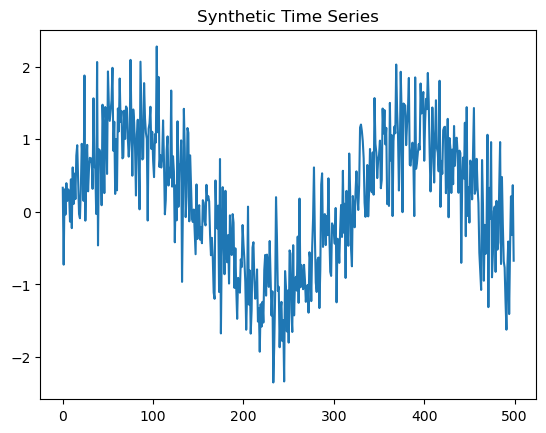

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input

def generate_data(n_points=500):
    x = np.arange(n_points)
    y = np.sin(0.02 * x) + 0.5 * np.random.normal(size=n_points)
    return y

data = generate_data(n_points=500)

plt.plot(data)
plt.title("Synthetic Time Series")
plt.show()



In [5]:
scaler = MinMaxScaler()

data_scaled = scaler.fit_transform(
    data.reshape(-1, 1)
)

def create_sequences(data, seq_length):
    X = []
    y = []

    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])

    return np.array(X), np.array(y)

seq_length = 20

X, y = create_sequences(
    data_scaled,
    seq_length
)

X = X.reshape(
    (X.shape[0], X.shape[1], 1)
)

model = Sequential([
    Input(shape=(seq_length, 1)),
    LSTM(50, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()



Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.1419 - val_loss: 0.0488
Epoch 2/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0264 - val_loss: 0.0265
Epoch 3/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0177 - val_loss: 0.0176
Epoch 4/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0154 - val_loss: 0.0194
Epoch 5/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0147 - val_loss: 0.0170
Epoch 6/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0144 - val_loss: 0.0178
Epoch 7/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0139 - val_loss: 0.0172
Epoch 8/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0138 - val_loss: 0.0189
Epoch 9/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0140 - val_loss: 0.0173
Epoch 10/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0138 - val_loss: 0.0177
Epoch 11/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0142 - val_loss: 0.0187
Epoch 12/20
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0

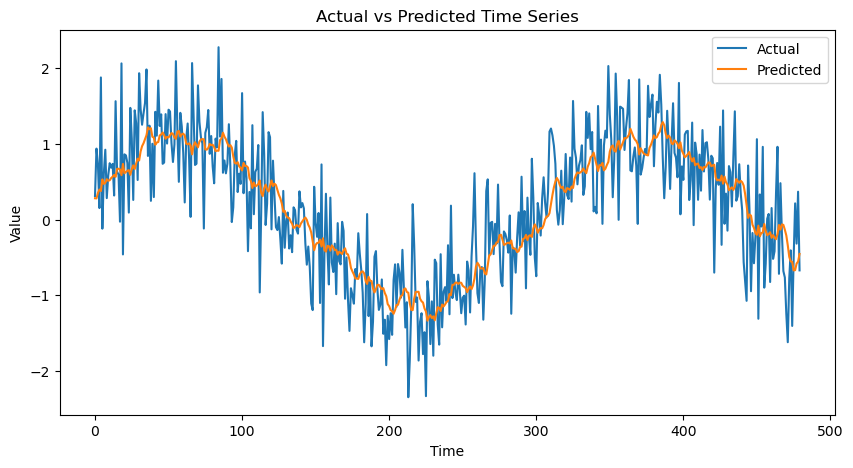

In [6]:
history = model.fit(
    X,
    y,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

predictions = model.predict(X)

predictions = scaler.inverse_transform(
    predictions
)

actual = scaler.inverse_transform(y)

rmse = np.sqrt(
    np.mean((actual - predictions) ** 2)
)

mae = np.mean(
    np.abs(actual - predictions)
)

print("RMSE:", rmse)
print("MAE:", mae)

plt.figure(figsize=(10, 5))

plt.plot(
    actual,
    label="Actual"
)

plt.plot(
    predictions,
    label="Predicted"
)

plt.title(
    "Actual vs Predicted Time Series"
)

plt.xlabel("Time")
plt.ylabel("Value")

plt.legend()

plt.show()